# Exponenttruncatie: bronschaal, schaal ×64 en afrondingscontrole

Deze notebook presenteert één vooraf vastgelegde **post-hocevaluatie** van twee bestaande 100-epochtrainingen:

- **Direct getraind:** de drie MX-gewichtsprecisies werden tijdens de training rechtstreeks uit de bron bepaald.
- **Met naïeve truncatie getraind:** E2M3 ontstond via exponenttruncatie uit E4M3; E2M1 daarna via mantissatruncatie, met behoud van de E4M3-bronschaal.

Elke training houdt haar eigen **epoch-100-checkpoint** en haar reeds opgeslagen **E4M3-best-checkpoint**. De notebook toont die vier groepen afzonderlijk. Zij kiest geen nieuw checkpoint, route of schaal. De drie oorspronkelijke gewichtmodi worden opnieuw geëvalueerd als referentie; daarnaast worden zes A/B/C-routes uit dezelfde opgeslagen E4M3-bron afgeleid.

**A32, de opgeslagen BN-bank van de doelprecisie en alle overige modelparameters blijven vast.** De evaluator gebruikt de opgeslagen MX-export, zonder de zes FP32-gewichtmasters te openen. Deze notebook leest uitsluitend JSON, CSV en NPZ; zij voert zelf geen inferentie of training uit.

## 1. Resultaatmap

Open bij voorkeur de kopie in de nieuwe evaluatiemap. Vul anders hieronder het volledige pad naar die map in. Dit is de map met `run_report.json`, `metrics.csv` en de submappen `direct` en `truncation`.

`SAVE_FIGURES = False` toont alle figuren zonder bestanden te schrijven. Zet dit alleen op `True` wanneer je PNG- en PDF-versies wilt bewaren; dan ontstaat een nieuwe analysemap en blijven de ruwe resultaten behouden. Er wordt geen uitgevoerde notebook opgeslagen.

In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_scale64_posthoc_eval\\20261024_141007_760930_evaluate')
SAVE_FIGURES = False  # Zet op True om PNG/PDF in een nieuwe analysemap te bewaren.


In [2]:
import importlib.util
import sys
import pandas as pd
from IPython.display import display, Markdown

helper_path = RUN_DIR.resolve() / "notebook_support.py"
if not helper_path.is_file():
    helper_path = Path.cwd() / "notebook_support.py"
if not helper_path.is_file():
    raise FileNotFoundError("Plaats deze notebook en notebook_support.py samen in de evaluatiemap en stel RUN_DIR in.")
spec = importlib.util.spec_from_file_location("mx_scale64_notebook_support", helper_path)
ns = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = ns
spec.loader.exec_module(ns)

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_colwidth", 70)
run = ns.load_run(RUN_DIR, verify_per_image=True)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.diagnostics_table(run))

**Geen volledig bevestigde evaluatie.** Bekijk eerst de meldingen; ontbrekende of ongeldige scores worden niet als eindresultaat voorgesteld.

Deze notebook leest opgeslagen resultaten. Zij voert geen modelevaluatie, training of BN-herkalibratie uit. De schaaloffset +6 is vooraf vastgelegd; er wordt geen schaal, route of checkpoint op deze resultaten geselecteerd.

,Niveau,Melding
0,FOUT,Rapport en CSV bevatten verschillende metrieken.
1,FOUT,truncation/last_epoch: B4: CE-gemiddelde wijkt af.
2,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() is deprecated. Please...
3,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is deprecated. Please ...


## 2. Wat vergelijken we?

Noem de E4M3-blokschaal **S** en de gedecodeerde lokale E4M3-waarde **u**; het opgeslagen brongewicht is dus **S × u**.

| Familie | E2M3-bewerking | Blokschaal | E2M1-bewerking |
|---|---|---|---|
| A | Behoud teken, hoogste twee van vier exponentbits en alle drie mantissabits | S | Verwijder de laagste twee mantissabits van A6 |
| B | Exact dezelfde elementcodes als A6 | 64S | Dezelfde mantissatruncatie vanuit B6 |
| C | Rond **u / 64** af naar E2M3, nearest-even | 64S | Dezelfde mantissatruncatie vanuit C6 |

**A → B** verandert alleen de schaal; elk gedecodeerd B-gewicht is 64 keer zijn A-tegenhanger. **B → C** vergelijkt twee codeconstructies bij dezelfde vooraf gekozen schaal 64S. C hergebruikt uitsluitend de opgeslagen E4M3-informatie. Er wordt geen nieuwe per-blokschaal bepaald.

Deze controle test of gewone afronding vanuit diezelfde bron bij 64S beter werkt dan exponent-MSB-behoud. C is geen bovengrens op de netwerkaccuracy. De vaste BN-statistieken kunnen op een gewichtsverandering reageren; de twee accuracyverschillen vormen geen onafhankelijke, optelbare causale verklaring. De mantissatruncatie blijft in alle vierbitsroutes aanwezig.

In [3]:
display(ns.route_table())

,Route,Beschrijving,Doelbits,Activatiebits,BN-bank,Bewerking,Schaal
0,source8,"E4M3-bron, ongewijzigd",8,32,8,Herhaling opgeslagen gewichtsmodus,Zoals opgeslagen bij deze training
1,trained6,E2M3 zoals getraind,6,32,32,Herhaling opgeslagen gewichtsmodus,Zoals opgeslagen bij deze training
2,trained4,E2M1 zoals getraind,4,32,4,Herhaling opgeslagen gewichtsmodus,Zoals opgeslagen bij deze training
3,A6,A · naïeve exponenttruncatie,6,32,32,Exponent-MSB-behoud,E4M3-bronschaal S
4,A4,A · exponent + mantissa,4,32,4,Exponent-MSB-behoud; daarna dezelfde mantissatruncatie E2M3 → E2M1,E4M3-bronschaal S
5,B6,"B · naïeve exponenttruncatie, schaal ×64",6,32,32,Exponent-MSB-behoud,64 × E4M3-bronschaal S
6,B4,"B · exponent + mantissa, schaal ×64",4,32,4,Exponent-MSB-behoud; daarna dezelfde mantissatruncatie E2M3 → E2M1,64 × E4M3-bronschaal S
7,C6,"C · afronden vanuit E4M3, schaal ×64",6,32,32,RNE_E2M3(decoded_E4M3 / 64),64 × E4M3-bronschaal S
8,C4,"C · afgeronde E2M3 → mantissa, schaal ×64",4,32,4,RNE_E2M3(decoded_E4M3 / 64); daarna dezelfde mantissatruncatie E2M...,64 × E4M3-bronschaal S


## 3. Hoofdresultaat: accuracy op beide vaste checkpoints

Elke training krijgt een eigen figuur met **epoch 100** links en **E4M3-best** rechts. Ook wanneer een lagere precisie een hogere accuracy haalt, blijft de eerder gekozen E4M3-best-rol ongewijzigd. De referentiebalken zijn de opnieuw gemeten oorspronkelijke modi van de desbetreffende training; bij de truncatietraining kunnen zij daarom samenvallen met A.

De tabellen tonen naast percentages ook de aantallen correcte voorspellingen en hard cross-entropy. Bij ontbrekende of inconsistente metriekgegevens wordt geen volledige accuracyfiguur ingevuld. Controleer altijd eerst de status bovenaan.

,training,role,epoch,path,Beschrijving,weight_bits,correct1,n,top1_percent,hard_cross_entropy
9,direct,last_epoch,100,source8,"E4M3-bron, ongewijzigd",8,24694,26032,94.860172,2.362200e-01
10,direct,last_epoch,100,trained6,E2M3 zoals getraind,6,24732,26032,95.006146,2.004032e-01
11,direct,last_epoch,100,trained4,E2M1 zoals getraind,4,24749,26032,95.071451,1.862470e-01
12,direct,last_epoch,100,A6,A · naïeve exponenttruncatie,6,4149,26032,15.938076,2.274756e+00
13,direct,last_epoch,100,A4,A · exponent + mantissa,4,4149,26032,15.938076,2.274692e+00
14,direct,last_epoch,100,B6,"B · naïeve exponenttruncatie, schaal ×64",6,5319,26032,20.432545,5.105308e+02
15,direct,last_epoch,100,B4,"B · exponent + mantissa, schaal ×64",4,5795,26032,22.261063,1.968135e+02
16,direct,last_epoch,100,C6,"C · afronden vanuit E4M3, schaal ×64",6,24728,26032,94.990781,2.003684e-01
17,direct,last_epoch,100,C4,"C · afgeronde E2M3 → mantissa, schaal ×64",4,24553,26032,94.318531,2.123594e-01
0,direct,best_E4M3_test,54,source8,"E4M3-bron, ongewijzigd",8,24740,26032,95.036878,2.141393e-01


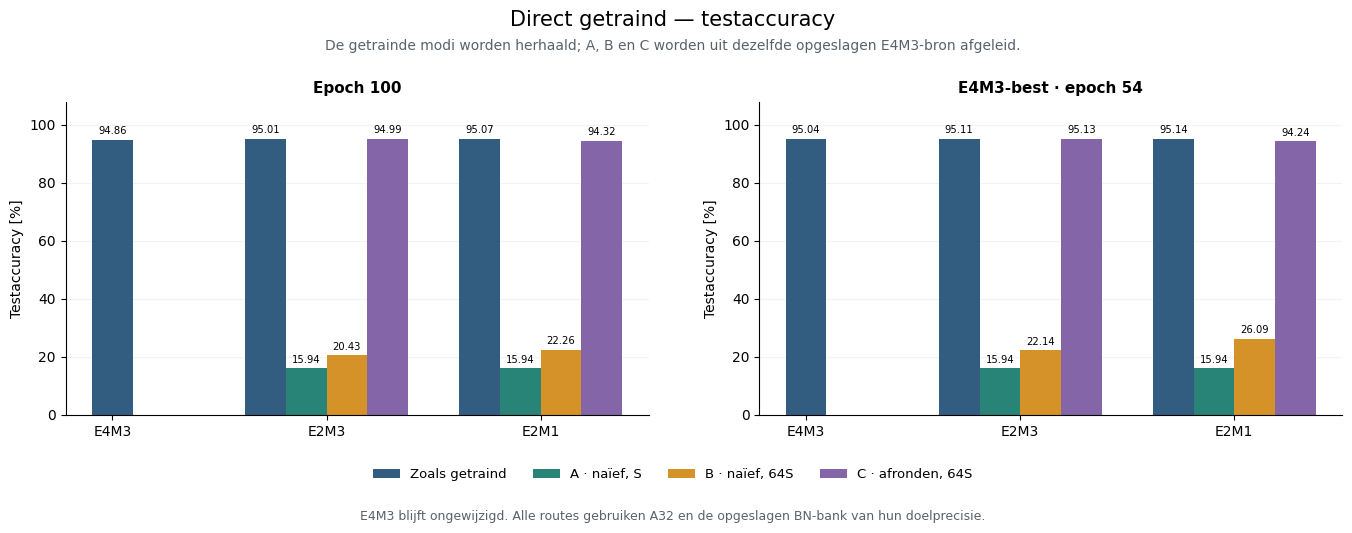

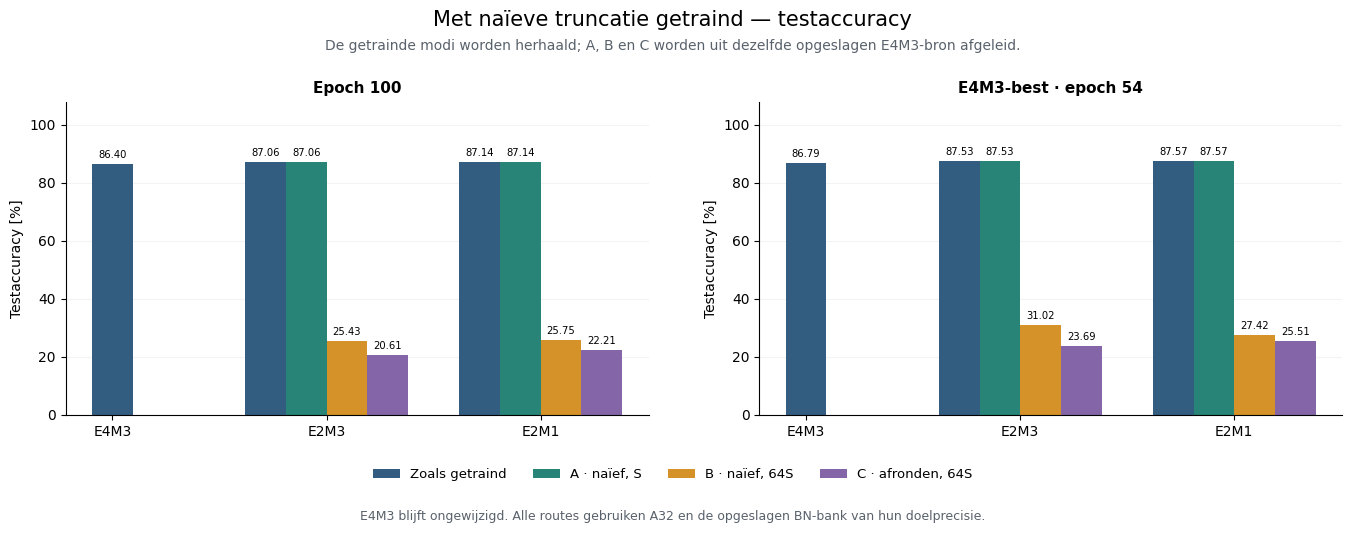

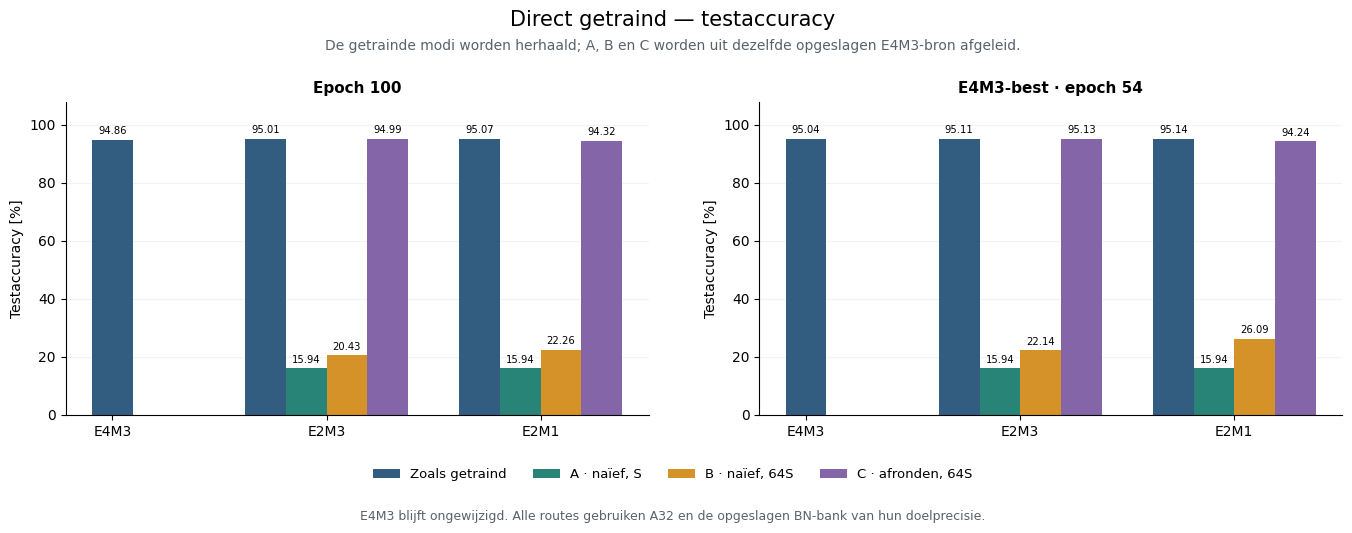

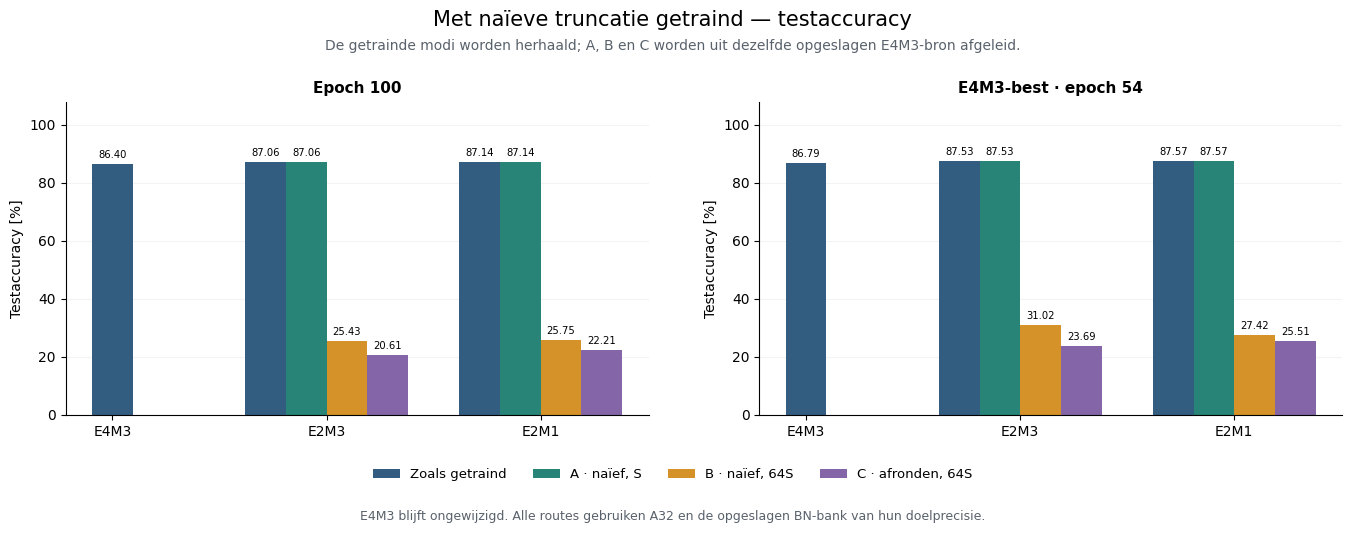

In [4]:
display(ns.accuracy_table(run))
figures["accuracy_direct"] = ns.plot_checkpoint_accuracy(run, "direct")
display(figures["accuracy_direct"])
figures["accuracy_truncation"] = ns.plot_checkpoint_accuracy(run, "truncation")
display(figures["accuracy_truncation"])

## 4. Afzonderlijke verschillen: schaal en afronding

Een positieve balk betekent een hogere accuracy bij de nieuwe route. **B − A** laat de verandering door schaal ×64 zien bij gelijke codes. **C − B** laat de verandering door elementafronding zien bij gelijke schaal 64S. De volledige deltatafel bevat ook de verschillen met de oorspronkelijke getrainde doelmodus en C − A.

Vergelijk eerst binnen dezelfde training en checkpointrol. Verschillen tussen de twee trainingspopulaties zijn beschrijvend; deze proef bevat geen herhaalde trainingsseeds of onzekerheidsmeting over trainingen.

,training,role,epoch,Vergelijking,Delta accuracy [pp],Netto correcte beelden
0,direct,last_epoch,100,A6 − trained6,-79.068070,-20583
1,direct,last_epoch,100,A4 − trained4,-79.133374,-20600
2,direct,last_epoch,100,B6 − trained6,-74.573602,-19413
3,direct,last_epoch,100,B4 − trained4,-72.810387,-18954
4,direct,last_epoch,100,C6 − trained6,-0.015366,-4
5,direct,last_epoch,100,C4 − trained4,-0.752919,-196
6,direct,last_epoch,100,B6 − A6,4.494468,1170
7,direct,last_epoch,100,B4 − A4,6.322987,1646
8,direct,last_epoch,100,C6 − B6,74.558236,19409
9,direct,last_epoch,100,C4 − B4,72.057468,18758


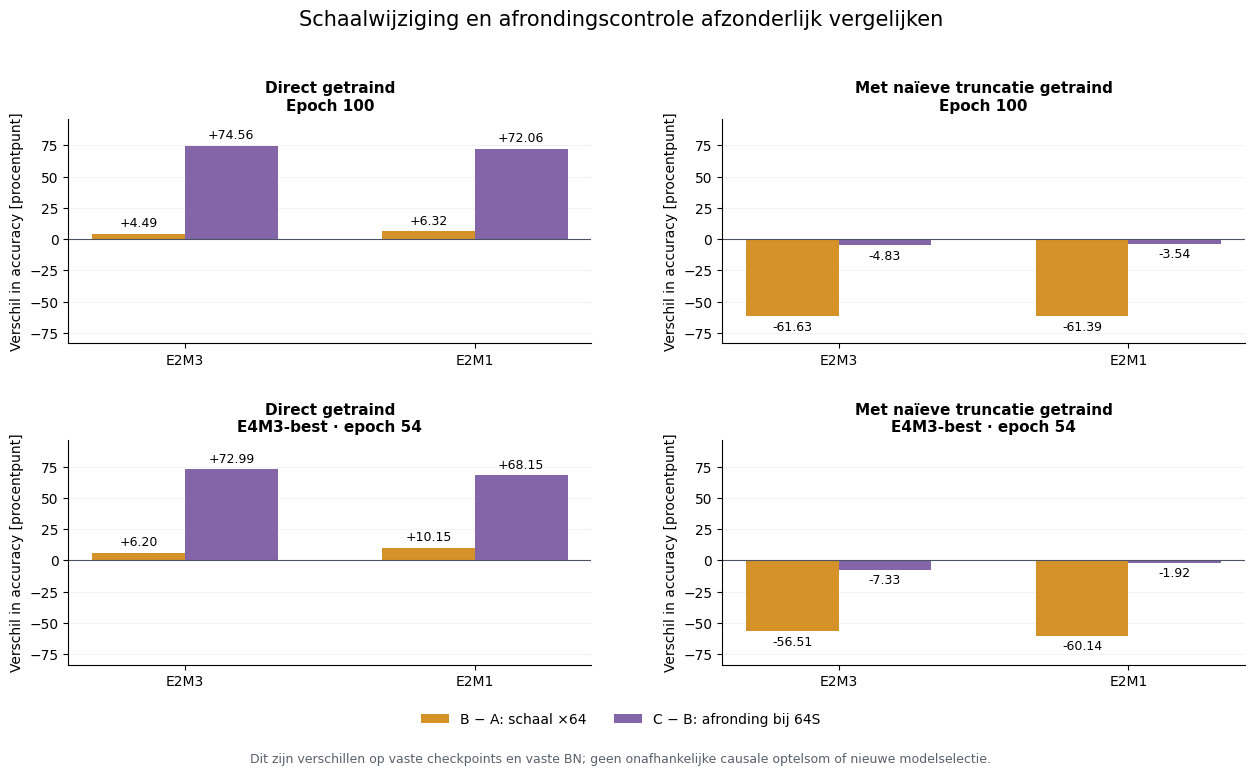

In [5]:
display(ns.delta_table(run))
figures["accuracy_deltas"] = ns.plot_accuracy_deltas(run)
display(figures["accuracy_deltas"])

## 5. Welke voorspellingen veranderen?

De figuur splitst elke vergelijking op in beelden die van fout naar correct gaan en beelden die van correct naar fout gaan. Het verschil tussen die twee aandelen is de accuracydelta. Ook veranderingen van het ene verkeerde cijfer naar een ander verkeerd cijfer worden in de tabel bijgehouden.

De helper controleert de opgeslagen per-beeldvoorspellingen en logits, de aantallen, de gemiddelde cross-entropy en alle gepaarde vergelijkingen opnieuw. Gelijke maximale logits zijn toegestaan: de door de evaluator opgeslagen topk-keuze hoeft bij een tie niet gelijk te zijn aan NumPy-argmax.

,Training,Rol,Epoch,Testbeelden,Checksum,Negen routes,Gepaarde tellingen
0,Direct getraind,last_epoch,100,26032,PASS,PASS,PASS
1,Direct getraind,best_E4M3_test,54,26032,PASS,PASS,PASS
2,Met naïeve truncatie getraind,best_E4M3_test,54,26032,PASS,PASS,PASS


,training,role,epoch,reference_path,other_path,prediction_changes,wrong_to_correct,correct_to_wrong,wrong_to_other_wrong,net_correct_change,accuracy_difference_pp
0,direct,best_E4M3_test,54,trained6,A6,21915,149,20760,1006,-20611,-79.175630
1,direct,best_E4M3_test,54,trained6,B6,20195,152,19149,894,-18997,-72.975569
2,direct,best_E4M3_test,54,trained6,C6,97,41,38,18,3,0.011524
3,direct,best_E4M3_test,54,trained4,A4,21934,165,20782,987,-20617,-79.198679
4,direct,best_E4M3_test,54,trained4,B4,19162,165,18140,857,-17975,-69.049631
5,direct,best_E4M3_test,54,trained4,C4,985,288,522,175,-234,-0.898894
6,direct,best_E4M3_test,54,A6,B6,26032,5763,4149,16120,1614,6.200061
7,direct,best_E4M3_test,54,A4,B4,26029,6788,4146,15095,2642,10.149047
8,direct,best_E4M3_test,54,B6,C6,20188,19149,149,890,19000,72.987093
9,direct,best_E4M3_test,54,B4,C4,19138,17927,186,1025,17741,68.150738


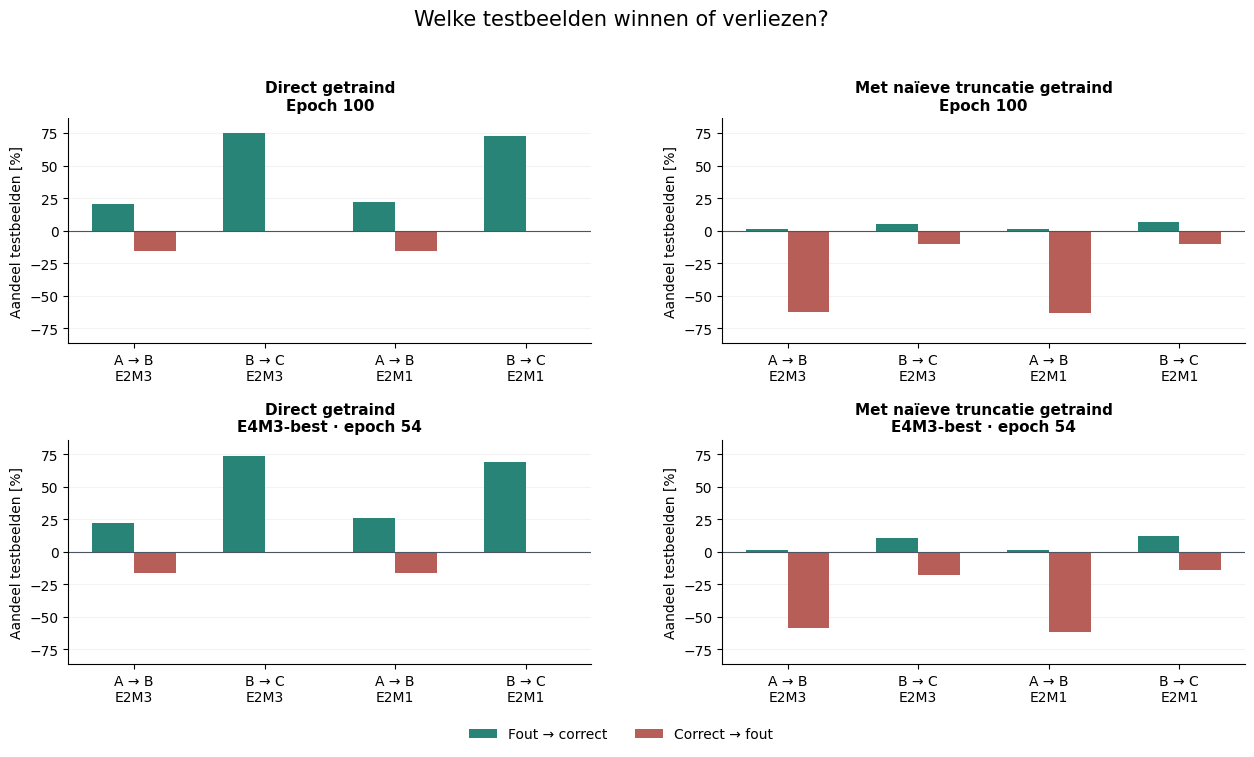

In [6]:
display(pd.DataFrame(run.output_checks))
if not run.pairs.empty:
    columns = [c for c in ["training", "role", "epoch", "reference_path", "other_path", "prediction_changes", "wrong_to_correct", "correct_to_wrong", "wrong_to_other_wrong", "net_correct_change", "accuracy_difference_pp"] if c in run.pairs]
    display(run.pairs[columns])
figures["paired_changes"] = ns.plot_paired_changes(run)
display(figures["paired_changes"])

## 6. Gewichtsgrootte en numerieke afwijking

Beide figuren gebruiken **dezelfde opgeslagen E4M3-bron** als gemeenschappelijke referentie per checkpoint. RMS laat de gewichtsgrootte zien; relatieve L2-afwijking is `||W_route − W_E4M3||₂ / ||W_E4M3||₂` per MX-laag. Een kleinere numerieke afwijking garandeert geen hogere accuracy. De FP32-master is geen referentie in deze proef.

Volle lijnen horen bij E2M3; stippellijnen bij E2M1. De laaglabels verwijzen naar de zes bestaande MX-convolutielagen. Bij een nulnorm kan een relatieve afwijking ongedefinieerd zijn; die wordt niet als nul ingevuld.

De samenvatting toont het bereik van de RMS-verhouding over de zes lagen en het totale aantal nulgewichten. A gebruikt S; B en C gebruiken doelbewust 64S. In de ruwe laagdiagnostiek verwijzen de historische veldnamen `*_to_direct` naar de **opgeslagen getrainde doelmodus van dezelfde training**, ook bij de truncatietraining. Cross-formaatcodebytes zijn geen vergelijkbare numerieke foutmaat.

,training,role,path,rms_ratio_min,rms_ratio_max,nulgewichten,aantal_gewichten,schaaloffset
0,direct,best_E4M3_test,source8,1.000000,1.000000,2,129472,0
1,direct,best_E4M3_test,trained6,1.000000,1.000000,2738,129472,0
2,direct,best_E4M3_test,trained4,1.000000,1.000000,11173,129472,0
3,direct,best_E4M3_test,A6,0.032520,0.038002,10,129472,0
4,direct,best_E4M3_test,A4,0.028302,0.033050,38,129472,0
5,direct,best_E4M3_test,B6,2.081294,2.432133,10,129472,6
6,direct,best_E4M3_test,B4,1.811319,2.115218,38,129472,6
7,direct,best_E4M3_test,C6,1.000095,1.000210,2917,129472,6
8,direct,best_E4M3_test,C4,0.878346,0.888500,18887,129472,6
9,direct,last_epoch,source8,1.000000,1.000000,0,129472,0


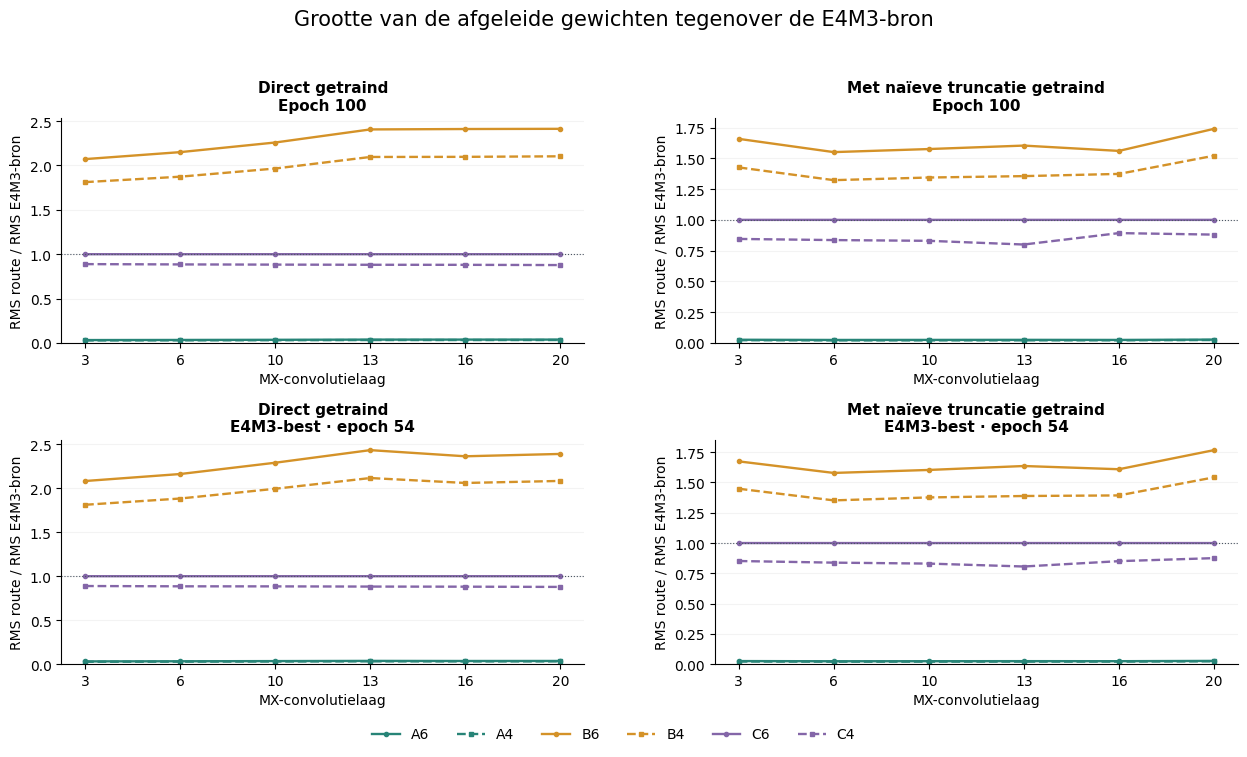

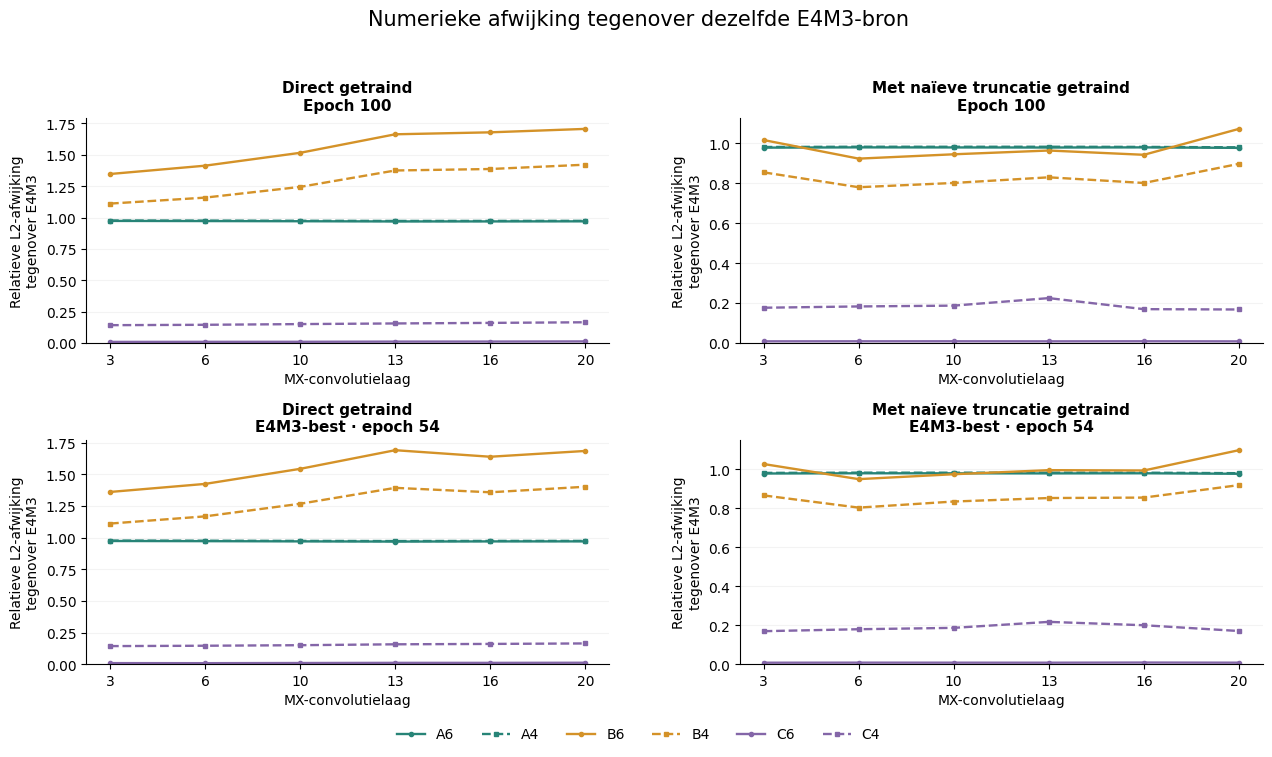

In [7]:
if not run.codes.empty and {"training", "role", "path", "rms_ratio_to_source", "zero_count", "n_weights", "scale_exponent_offset"} <= set(run.codes):
    code_summary = run.codes.groupby(["training", "role", "path"], sort=False).agg(
        rms_ratio_min=("rms_ratio_to_source", "min"), rms_ratio_max=("rms_ratio_to_source", "max"),
        nulgewichten=("zero_count", "sum"), aantal_gewichten=("n_weights", "sum"),
        schaaloffset=("scale_exponent_offset", "first")).reset_index()
    display(code_summary)
figures["weight_magnitudes"] = ns.plot_weight_magnitudes(run)
display(figures["weight_magnitudes"])
figures["weight_differences"] = ns.plot_weight_differences(run)
display(figures["weight_differences"])

## 7. Concentratie op één voorspelde klasse

Een lage accuracy kan samengaan met een vrijwel constante voorspelling. Daarom tonen we per route het aandeel van het meest voorspelde cijfer en het aantal verschillende voorspelde klassen. Eén klasse met 100% concentratie is een geldig gemeten resultaat; het is geen reden om die route uit de vergelijking te verwijderen.

Deze diagnose vervangt de accuracy niet. Zij helpt verklaren of een route nog gevarieerde voorspellingen produceert en of schaal ×64 of afronding dat patroon verandert.

,training,role,epoch,path,classes_predicted,dominant_class,dominant_fraction,n
0,direct,last_epoch,100,source8,10,1,0.196758,26032
1,direct,last_epoch,100,trained6,10,1,0.197180,26032
2,direct,last_epoch,100,trained4,10,1,0.196796,26032
3,direct,last_epoch,100,A6,1,2,1.000000,26032
4,direct,last_epoch,100,A4,1,2,1.000000,26032
5,direct,last_epoch,100,B6,8,0,0.579095,26032
6,direct,last_epoch,100,B4,9,0,0.549247,26032
7,direct,last_epoch,100,C6,10,1,0.196911,26032
8,direct,last_epoch,100,C4,10,1,0.190727,26032
9,direct,best_E4M3_test,54,source8,10,1,0.197372,26032


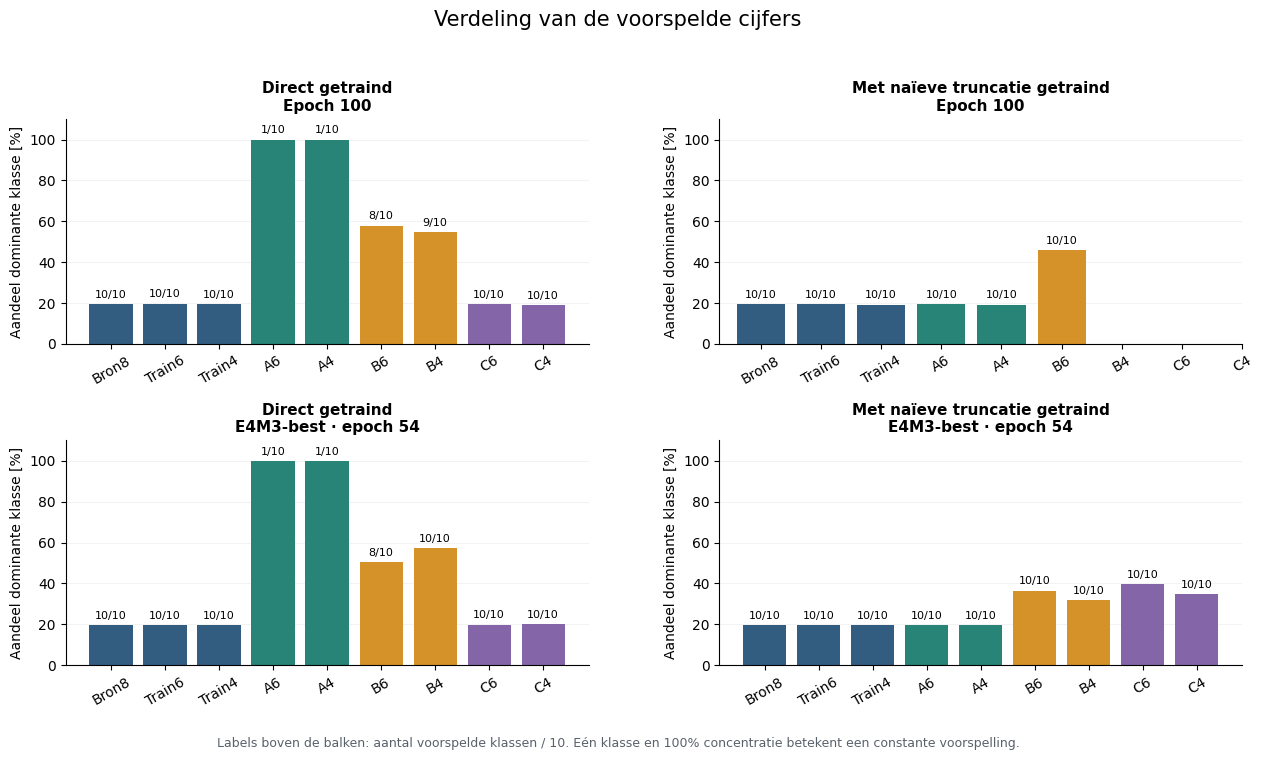

In [8]:
prediction_summary = ns.prediction_table(run)
if not prediction_summary.empty:
    display(prediction_summary[["training", "role", "epoch", "path", "classes_predicted", "dominant_class", "dominant_fraction", "n"]])
figures["prediction_diversity"] = ns.plot_prediction_diversity(run)
display(figures["prediction_diversity"])

## 8. Herhaling, vaste selectie en interpretatie

De historische herhalingscontrole vergelijkt de drie oorspronkelijke modi met de opgeslagen trainingresultaten. Een verschil wordt zichtbaar gerapporteerd. Gebruik bij de A/B/C-vergelijking altijd de huidige meting op dezelfde testbeelden; verwar een eventuele herhalingsafwijking niet met een truncatie-effect.

De audittabel bewaart per training en checkpoint de oorspronkelijke identiteit en bevestigt de vaste model- en BN-toestand. Er zijn nul optimizerupdates. De testset wordt eenmaal in dezelfde vaste volgorde per route verwerkt; train- en extra-data worden niet gebruikt.

Bespreek de uitkomst in deze volgorde: (1) reproduceert de oorspronkelijke modus, (2) wat doet A → B, (3) wat doet B → C, (4) komt dat overeen met gewichts- en voorspeldiagnostiek, en (5) verschillen die patronen tussen de twee trainingen? Een eventuele volgende trainingsproef volgt pas na beoordeling van deze resultaten.

In [9]:
display(run.reproduction)
display(ns.audit_table(run))
display(Markdown(ns.timing_markdown(run)))
for limitation in run.report.get("limitations", []):
    display(Markdown("- " + str(limitation)))

,training,role,epoch,path,historical_correct1,reevaluated_correct1,difference_correct1,accuracy_difference_pp,historical_ce,reevaluated_ce,correct1_matches_history
0,direct,best_E4M3_test,54,source8,24740,24740,0,0.0,0.214139,0.214139,True
1,direct,best_E4M3_test,54,trained6,24760,24760,0,0.0,0.189812,0.189812,True
2,direct,best_E4M3_test,54,trained4,24766,24766,0,0.0,0.182220,0.182220,True
3,direct,last_epoch,100,source8,24694,24694,0,0.0,0.236220,0.236220,True
4,direct,last_epoch,100,trained6,24732,24732,0,0.0,0.200403,0.200403,True
5,direct,last_epoch,100,trained4,24749,24749,0,0.0,0.186247,0.186247,True
6,truncation,best_E4M3_test,54,source8,22594,22594,0,0.0,0.430299,0.430299,True
7,truncation,best_E4M3_test,54,trained6,22786,22786,0,0.0,0.415061,0.415061,True
8,truncation,best_E4M3_test,54,trained4,22795,22795,0,0.0,0.420402,0.420402,True
9,truncation,last_epoch,100,source8,22491,22491,0,0.0,0.436818,0.436818,True


,Training,Rol,Epoch,Model/BN ongewijzigd,Geen gradients,Optimizerupdates,BN-herkalibratie,Zes masters afwezig,Checkpoint-SHA256
0,Direct getraind,last_epoch,100,True,True,0,False,True,987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339
1,Direct getraind,best_E4M3_test,54,True,True,0,False,True,ab2e05d40d82cccc971aa117cd08f5182174bc44b9f4b4919a829c3275f7e8c4
2,Met naïeve truncatie getraind,last_epoch,100,True,True,0,False,True,d011fb555e27e3a87e881314851e4edbc30c39a76acabcae2d78dd5c27151d8a
3,Met naïeve truncatie getraind,best_E4M3_test,54,True,True,0,False,True,751d2dda8ba731329c4d7502d35aaec08cbc422f7bc6acd36c3010c90cc95d96


**Gemeten evaluatiesessie: 0.52 minuten.** Deze tijd omvat alle routes en administratie. Het is geen native-MX-snelheids- of energiebenchmark.

- Two separate trained model populations; never mix checkpoints or BN state across populations.

- Stored E4-best and epoch100 are fixed; no new selection, fitting or training occurs.

...

- One training seed; the two checkpoints of one run are not independent repetitions.

- FP32 decoded buffers emulate MX; no native-kernel speed or energy claim.

- Six quantized FP32 masters are absent; FP32 exception layers and BN auxiliary state remain.

- Low accuracy is an outcome, not a software FAIL; historical mismatches are reported.

- CUDA repeatability is not bit-exact under the original backend policy.

## 9. Figuren bewaren

Alleen de volgende cel schrijft bestanden wanneer `SAVE_FIGURES` bovenaan op `True` staat. De nieuwe map bevat zeven PNG-figuren, zeven PDF-figuren en herkomstinformatie. Bestaande resultaatbestanden en notebooks worden behouden.

In [10]:
if SAVE_FIGURES:
    saved_to = ns.save_figures(run, figures)
    print("Figuren bewaard in:", saved_to)
else:
    print("Figuren alleen getoond; geen analysebestanden geschreven.")

Figuren alleen getoond; geen analysebestanden geschreven.
